# Aşama 11: Performans

Analiz tarafı bitti; şimdi aynı hesapları **daha hızlı** yapıp kazandığımız zamanı daha kesin bir sonuca harcıyoruz. İki teknik:

1. **Daha akıllı algoritma:** Her fit'te genel amaçlı bir optimize edici yerine, problemin matematiğine özel **Newton yöntemi**.
2. **Paralel hesaplama:** Monte Carlo denemeleri birbirinden bağımsız; aynı anda birden fazla çekirdekte çalıştırılabilir. Şimdiye kadar hep tek çekirdek kullandık.

Sonunda kazancı Aşama 7'ye geri yatırıyoruz: 30 yerine **200** karıştırılmış gökyüzü haritasıyla daha kesin bir post-trial anlamlılık.

In [1]:
import sys; sys.path.append('../src')
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import icecube_ps as ps
importlib.reload(ps)
assert float(ps.SURUM) >= float('11.0'), f"src/icecube_ps.py eski sürüm ({getattr(ps, 'SURUM', 'yok')}). Yenisini kopyala, kernel'i yeniden başlat."
try:
    from tqdm.auto import tqdm          # ilerleme çubuğu
except ImportError:
    tqdm = None

pd.set_option('display.float_format', '{:.3g}'.format)
DATA, RESULTS = Path('../data'), Path('../results')
ev = ps.veri_yukle(DATA)
B = ps.ArkaPlan(ev['dec'].values)
print('icecube_ps', ps.SURUM, '| olay:', f'{len(ev):,}')
import os, time
N_CEKIRDEK = os.cpu_count()
print('Mantıksal çekirdek sayısı:', N_CEKIRDEK)

icecube_ps 14.0 | olay: 1,134,450
Mantıksal çekirdek sayısı: 12


c:\Users\musab\Desktop\Projects\Claude_Notrino_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Newton yöntemi

Likelihood'u maksimize etmek, türevini sıfır yapan nₛ'i bulmak demek:

$$f(n_s) = \sum_i \frac{x_i}{N + n_s x_i} - \frac{N-n}{N-n_s} = 0, \qquad x_i = \frac{S_i}{B_i} - 1$$

Newton yöntemi (Calculus 1'deki teğet doğrusu fikri) bu kökü 4–6 adımda buluyor: $n_{s} \leftarrow n_{s} - f/f'$. Genel amaçlı optimize edici ise türevi bilmediği için ~20 kez fonksiyonu hesaplıyordu.

Önce iki yöntemin **aynı sonucu** verdiğini, sonra hız farkını kontrol ediyoruz.

In [2]:
L = ps.NoktaKaynakLikelihood(ev, B, *ps.KAYNAKLAR['NGC 1068'])
rng = np.random.default_rng(1)
sb_listesi = [L.sb_orani(rng.uniform(0, 360, len(L.ra_bant))) for _ in range(300)]
sb_listesi.append(L.sb_orani())                       # gerçek gökyüzü de dahil

t = time.perf_counter(); eski = [ps.ns_fit_scipy(sb, L.N) for sb in sb_listesi]; t_eski = time.perf_counter() - t
t = time.perf_counter(); yeni = [ps.ns_fit_newton(sb, L.N) for sb in sb_listesi]; t_yeni = time.perf_counter() - t
fark = max(abs(a[1] - b[1]) for a, b in zip(eski, yeni))
print(f'En büyük TS farkı: {fark:.1e}  (pratikte aynı)')
print(f'Genel optimize edici: {t_eski:.2f} s   |   Newton: {t_yeni:.2f} s   →  {t_eski / t_yeni:.1f} kat hızlı')

En büyük TS farkı: 2.7e-10  (pratikte aynı)
Genel optimize edici: 0.14 s   |   Newton: 0.02 s   →  5.8 kat hızlı


## 2. Paralel hesaplama: kaç çekirdek, kaç kat hız?

Aynı iş yükünü (NGC 1068 yönünde 1200 arka plan denemesi) farklı sayıda süreçle çalıştırıyoruz. Her süreç veriyi bir kere yüklüyor, sonra kendine düşen denemeleri yapıyor.

**İdeal** durumda 6 çekirdek 6 kat hız verir. Gerçekte biraz daha az: süreçleri başlatmak ve veriyi her birine yüklemek zaman alıyor (Amdahl yasası). Ryzen 7600X'te 6 fiziksel çekirdek var ama her biri 2 iş parçacığı çalıştırabildiği için 12 süreç de deniyoruz.

In [3]:
gorevler = [(*ps.KAYNAKLAR['NGC 1068'], 50, tohum) for tohum in range(24)]   # 24 × 50 = 1200 deneme
islem_sayilari = [n for n in [1, 2, 4, 6, 8, 12] if n <= N_CEKIRDEK]
sureler = {}
for n in islem_sayilari:
    t = time.perf_counter()
    ps.paralel(ps.gorev_nokta_arka_plan, gorevler, n, DATA.resolve())
    sureler[n] = time.perf_counter() - t
    print(f'{n:2d} süreç: {sureler[n]:6.1f} s   ({sureler[1] / sureler[n]:.1f} kat)')

 1 süreç:   11.5 s   (1.0 kat)
 2 süreç:    7.9 s   (1.5 kat)
 4 süreç:    5.2 s   (2.2 kat)
 6 süreç:    5.0 s   (2.3 kat)
 8 süreç:    5.3 s   (2.2 kat)
12 süreç:    6.1 s   (1.9 kat)


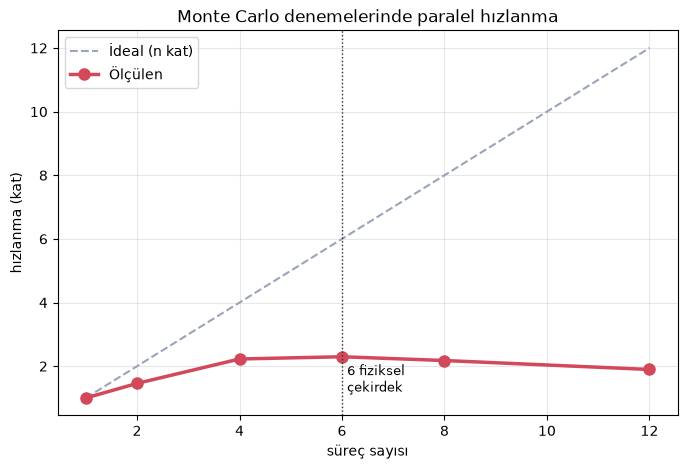

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
n = np.array(islem_sayilari)
hiz = np.array([sureler[1] / sureler[k] for k in n])
ax.plot(n, n, '--', color='#9aa5b8', label='İdeal (n kat)')
ax.plot(n, hiz, 'o-', color='#d1495b', lw=2.5, ms=8, label='Ölçülen')
ax.axvline(6, color='#333', ls=':', lw=1); ax.text(6.1, 1.2, '6 fiziksel\nçekirdek', fontsize=9)
ax.set_xlabel('süreç sayısı'); ax.set_ylabel('hızlanma (kat)')
ax.set_title('Monte Carlo denemelerinde paralel hızlanma'); ax.legend(); ax.grid(alpha=0.3)
plt.savefig(RESULTS / 'asama11_hizlanma.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Kazancı bilime yatırmak: Aşama 7'yi güçlendirmek

Aşama 7'de en sıcak noktanın düzeltilmiş anlamlılığını 30 karıştırılmış haritayla tahmin etmiştik. 30 harita az; tahminin kendisi belirsiz. Şimdi tüm çekirdeklerle **170 harita daha** ekleyip toplamı 200'e çıkarıyoruz.

⏱️ Birkaç dakika. Parça parça kaydediliyor, durdurup devam edebilirsin.

In [5]:
HEDEF = 200
eski = np.load(RESULTS / 'asama7_karisik_min_p.npy')
dosya = RESULTS / 'asama11_karisik_min_p.npy'
min_p = list(np.load(dosya)) if dosya.exists() else list(eski)
parti = 2 * N_CEKIRDEK
while len(min_p) < HEDEF:
    n_yeni = min(parti, HEDEF - len(min_p))
    tohumlar = [(0.7, 50_000 + len(min_p) + i) for i in range(n_yeni)]
    t = time.perf_counter()
    min_p += ps.paralel(ps.gorev_karisik_harita, tohumlar, N_CEKIRDEK, DATA.resolve())
    np.save(dosya, np.array(min_p))
    print(f'{len(min_p)}/{HEDEF} harita  ({(time.perf_counter() - t) / n_yeni:.1f} s/harita)', flush=True)
min_p = np.array(min_p)

30 harita:  N_eff ≈ 9,980  →  post-trial 1.55σ
200 harita: N_eff ≈ 12,072  →  post-trial 1.45σ  (bootstrap aralığı 1.42–1.48σ)
Doğrudan sayım: 17/200 karıştırılmış harita gerçekten daha sıcak


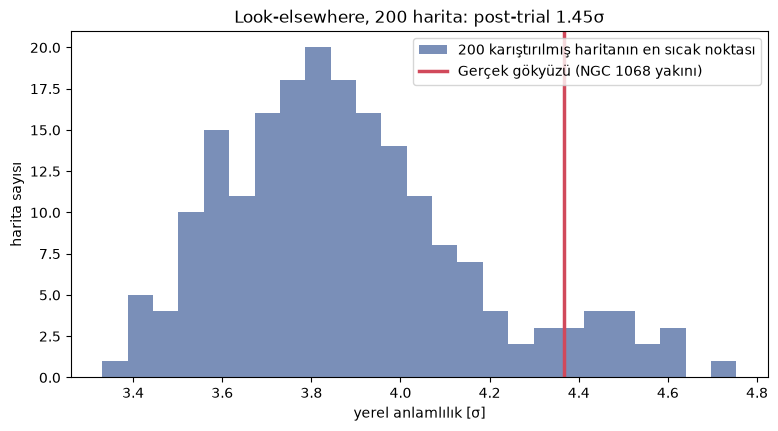

In [6]:
# Izgaradaki en büyük TS (karıştırılmış haritalarla aynı işlem; bkz. Aşama 7 notu)
p_yerel = ps.yerel_p(np.load(RESULTS / 'asama7_harita.npz')['ts'].max())

def post_trial(min_p_dizisi):
    N_eff = ps.etkin_deneme_sayisi(min_p_dizisi)
    return N_eff, ps.sigma(1 - (1 - p_yerel) ** N_eff)

N30, s30 = post_trial(min_p[:30])
N200, s200 = post_trial(min_p)
# Belirsizlik: haritaları yeniden örnekleyerek (bootstrap) N_eff tahmininin ne kadar oynadığına bak
rng = np.random.default_rng(5)
boot = np.array([post_trial(rng.choice(min_p, len(min_p)))[1] for _ in range(500)])
print(f'30 harita:  N_eff ≈ {N30:,.0f}  →  post-trial {s30:.2f}σ')
print(f'{len(min_p)} harita: N_eff ≈ {N200:,.0f}  →  post-trial {s200:.2f}σ  '
      f'(bootstrap aralığı {np.percentile(boot, 16):.2f}–{np.percentile(boot, 84):.2f}σ)')
print(f'Doğrudan sayım: {np.sum(min_p <= p_yerel)}/{len(min_p)} karıştırılmış harita gerçekten daha sıcak')

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(ps.sigma(min_p), bins=25, color='#7a8fb8', label=f'{len(min_p)} karıştırılmış haritanın en sıcak noktası')
ax.axvline(ps.sigma(p_yerel), color='#d1495b', lw=2.5, label='Gerçek gökyüzü (NGC 1068 yakını)')
ax.set_xlabel('yerel anlamlılık [σ]'); ax.set_ylabel('harita sayısı'); ax.legend()
ax.set_title(f'Look-elsewhere, {len(min_p)} harita: post-trial {s200:.2f}σ')
plt.savefig(RESULTS / 'asama11_post_trial_200.png', dpi=150, bbox_inches='tight')
plt.show()
pd.DataFrame([dict(n_harita=len(min_p), N_eff=N200, sigma_post=s200,
                   sigma_post_16=np.percentile(boot, 16), sigma_post_84=np.percentile(boot, 84),
                   sigma_post_30harita=s30)]).to_csv(RESULTS / 'asama11_post_trial.csv', index=False)

## Yorumlarken

- **Algoritma > donanım:** Newton yöntemi tek başına fit'leri birkaç kat hızlandırdı, hiçbir ek donanım gerekmeden. Matematiği bilmek koddan hız kazandırıyor.
- **Paralellik:** Ölçülen hızlanma ideal çizginin altında kalıyor; süreç başlatma ve veri yükleme gibi paralelleşemeyen kısımlar yüzünden. 6'dan sonra kazanç azalıyor çünkü fiziksel çekirdek sayısı 6.
- **Daha kesin sonuç:** 200 haritayla post-trial anlamlılık hem daha güvenilir hem de bir belirsizlik aralığıyla birlikte veriliyor. Bilimde bir sayıyı belirsizliğiyle birlikte vermek, tek bir sayı vermekten çok daha değerli.
- **Daha da hız için:** Sıradaki adım `numba` ile iç döngüleri derlemek ya da ekran kartını (GPU) kullanmak olurdu; bu projenin ölçeğinde gerek kalmadı.